# 01 · Linear Algebra, Vector Spaces and Tensor Mathematics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/01-linear-algebra/01_linear_algebra.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-01-linear-algebra.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 01](https://github.com/anuxlab/deep-learning-systems/wiki/Module-01) |
| **Level** | Foundational |
| **Typical CPU runtime** | < 1 min (GitHub free runner, no GPU) |
| **Prerequisites** | none |

## What you will do

- Predict shapes under broadcasting and matrix multiplication, and verify with code.
- Compute norms, projections and orthonormal bases (Gram–Schmidt / QR).
- Find rank and null space numerically and interpret eigenvalues/eigenvectors and the SVD geometrically.
- Apply the Eckart–Young theorem: best rank-$k$ approximation by truncated SVD.
- Use `einsum` for tensor contractions and understand memory layout (strides).

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

15:56:51 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43901829031
          commit: 91e223fc43e41a334729ca846bd3a2056f0611b5


## 1 · Shapes, indexing and broadcasting
**Broadcasting rule:** align shapes from the *right*; two dimensions are compatible if they are equal or one of them is 1. A size-1 dimension is virtually stretched (no copy).

A frequent deep-learning pattern: adding a bias vector $b\in\mathbb{R}^{d}$ to a batch $X\in\mathbb{R}^{B\times d}$.

In [2]:
X = np.arange(6).reshape(2, 3).astype(float)      # (2,3)
b = np.array([10., 20., 30.])                      # (3,)  -> broadcast to (2,3)
print("X+b =\n", X + b)
col = np.array([[100.], [200.]])                   # (2,1) -> broadcast to (2,3)
print("X+col =\n", X + col)
check((X + b).shape == (2, 3), "(2,3)+(3,) -> (2,3)")
# outer sum via broadcasting: (3,1)+(1,4) -> (3,4)
a = np.arange(3)[:, None]; c = np.arange(4)[None, :]
check((a + c).shape == (3, 4), "(3,1)+(1,4) -> (3,4)")
try:
    np.ones((2, 3)) + np.ones((2,))
except ValueError as e:
    print("incompatible shapes raise:", e)

X+b =
 [[10. 21. 32.]
 [13. 24. 35.]]
X+col =
 [[100. 101. 102.]
 [203. 204. 205.]]
  ✅ (2,3)+(3,) -> (2,3)
  ✅ (3,1)+(1,4) -> (3,4)
incompatible shapes raise: operands could not be broadcast together with shapes (2,3) (2,) 


## 2 · Dot products and matrix multiplication
For $A\in\mathbb{R}^{m\times n}$, $B\in\mathbb{R}^{n\times p}$: $(AB)_{ij}=\sum_k A_{ik}B_{kj}$. Three equivalent views: (i) rows·columns, (ii) $A$ applied to each column of $B$, (iii) sum of outer products of columns of $A$ with rows of $B$. We verify all three.

In [3]:
rng = np.random.default_rng(0)
A, B = rng.normal(size=(4, 5)), rng.normal(size=(5, 3))
C1 = A @ B
C2 = np.array([[A[i] @ B[:, j] for j in range(3)] for i in range(4)])          # row . column
C3 = np.column_stack([A @ B[:, j] for j in range(3)])                           # A acting on columns
C4 = sum(np.outer(A[:, k], B[k]) for k in range(5))                             # sum of outer products
for name, C in [("row·col", C2), ("columns", C3), ("outer sum", C4)]:
    check(np.allclose(C1, C), f"matmul view '{name}' matches A @ B")
check(np.allclose((A @ B).T, B.T @ A.T), "(AB)^T = B^T A^T")

  ✅ matmul view 'row·col' matches A @ B
  ✅ matmul view 'columns' matches A @ B
  ✅ matmul view 'outer sum' matches A @ B
  ✅ (AB)^T = B^T A^T


## 3 · Norms, distances, orthogonality and projections
$\|x\|_2=\sqrt{x^\top x}$, $\|x\|_1=\sum|x_i|$, $\|x\|_\infty=\max|x_i|$. Cauchy–Schwarz: $|x^\top y|\le\|x\|\|y\|$.
The projection of $b$ onto $\mathrm{span}(A)$ is $\hat b = A(A^\top A)^{-1}A^\top b$ — the least-squares solution — and the residual $b-\hat b$ is orthogonal to every column of $A$.

In [4]:
x = np.array([3., -4., 12.])
print("L1, L2, Linf:", np.abs(x).sum(), np.linalg.norm(x), np.abs(x).max())
y = rng.normal(size=3)
check(abs(x @ y) <= np.linalg.norm(x) * np.linalg.norm(y) + 1e-12, "Cauchy–Schwarz inequality")
check(np.linalg.norm(x + y) <= np.linalg.norm(x) + np.linalg.norm(y), "triangle inequality")

A = rng.normal(size=(20, 3)); b = rng.normal(size=20)
P = A @ np.linalg.inv(A.T @ A) @ A.T                      # projection matrix
b_hat = P @ b
check(np.allclose(P @ P, P), "P is idempotent (P^2 = P)")
check(np.allclose(P, P.T), "P is symmetric")
check(np.allclose(A.T @ (b - b_hat), 0, atol=1e-10), "residual is orthogonal to the column space")
w, *_ = np.linalg.lstsq(A, b, rcond=None)
check(np.allclose(A @ w, b_hat), "projection == least-squares fit")

L1, L2, Linf: 19.0 13.0 12.0
  ✅ Cauchy–Schwarz inequality
  ✅ triangle inequality
  ✅ P is idempotent (P^2 = P)
  ✅ P is symmetric
  ✅ residual is orthogonal to the column space
  ✅ projection == least-squares fit


### Gram–Schmidt and QR
Gram–Schmidt turns independent vectors into an **orthonormal basis**: $u_k = v_k-\sum_{j<k}(q_j^\top v_k)q_j$, $q_k=u_k/\|u_k\|$. We implement it and compare with `np.linalg.qr` (equal up to column signs).

In [5]:
def gram_schmidt(V):
    Q = np.zeros_like(V)
    for k in range(V.shape[1]):
        u = V[:, k] - Q[:, :k] @ (Q[:, :k].T @ V[:, k])
        Q[:, k] = u / np.linalg.norm(u)
    return Q
V = rng.normal(size=(6, 4))
Q = gram_schmidt(V)
check(np.allclose(Q.T @ Q, np.eye(4)), "Gram–Schmidt columns are orthonormal")
Qn, R = np.linalg.qr(V)
check(np.allclose(np.abs(Q), np.abs(Qn)), "matches numpy QR up to sign")

  ✅ Gram–Schmidt columns are orthonormal
  ✅ matches numpy QR up to sign


## 4 · Rank, null space, span
The **rank** is the dimension of the column space = number of non-zero singular values. The **null space** is $\{x: Ax=0\}$; by rank–nullity, $\operatorname{rank}+\dim\mathcal{N}=n$. We build a deliberately rank-deficient matrix and recover both from the SVD.

In [6]:
base = rng.normal(size=(6, 2)); M = base @ rng.normal(size=(2, 5))     # 6x5 matrix of rank 2
U, s, Vt = np.linalg.svd(M)
rank = int((s > 1e-10).sum())
null_basis = Vt[rank:].T                                              # right-singular vectors with sigma=0
print("singular values:", np.round(s, 6))
check(rank == np.linalg.matrix_rank(M) == 2, "rank = 2")
check(null_basis.shape[1] == M.shape[1] - rank, "rank–nullity: dim N = n - rank = 3")
check(np.allclose(M @ null_basis, 0, atol=1e-10), "M x = 0 for all null-space basis vectors")

singular values: [4.532252 3.236644 0.       0.       0.      ]
  ✅ rank = 2
  ✅ rank–nullity: dim N = n - rank = 3
  ✅ M x = 0 for all null-space basis vectors


## 5 · Linear maps, eigenvectors and the SVD — geometry
A matrix $A$ maps the unit circle to an ellipse. The SVD $A=U\Sigma V^\top$ says: rotate/reflect ($V^\top$), scale along axes by $\sigma_i$ ($\Sigma$), rotate/reflect ($U$). The semi-axes of the ellipse are $\sigma_i u_i$. Eigenvectors are the directions that only get *scaled*: $Av=\lambda v$.

singular values: [2.55833637 0.97719754] | eigenvalues: [2.5+0.j 1. +0.j]
  ✅ A v = λ v for every eigenpair
  ✅ A = U Σ V^T
  ✅ |det A| = product of singular values


15:56:52 | INFO | figure saved -> figures/svd_geometry.png


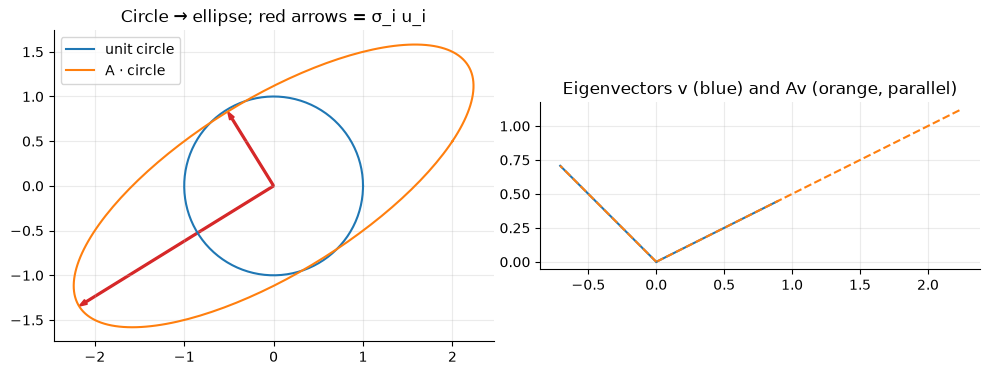

In [7]:
A = np.array([[2.0, 1.0], [0.5, 1.5]])
t = np.linspace(0, 2 * np.pi, 200); circle = np.vstack([np.cos(t), np.sin(t)])
ell = A @ circle
U, s, Vt = np.linalg.svd(A)
lam, W = np.linalg.eig(A)
print("singular values:", s, "| eigenvalues:", lam)
check(np.allclose(A @ W, W * lam), "A v = λ v for every eigenpair")
check(np.allclose(U @ np.diag(s) @ Vt, A), "A = U Σ V^T")
check(np.isclose(abs(np.linalg.det(A)), s.prod()), "|det A| = product of singular values")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ax[0].plot(*circle, label="unit circle"); ax[0].plot(*ell, label="A · circle")
for i in range(2):
    ax[0].arrow(0, 0, *(s[i] * U[:, i]), color="C3", width=0.02, length_includes_head=True)
ax[0].set_aspect("equal"); ax[0].set_title("Circle → ellipse; red arrows = σ_i u_i"); ax[0].legend()
for i in range(2):
    v = np.real(W[:, i]); ax[1].plot([0, v[0]], [0, v[1]], "C0"); Av = A @ v; ax[1].plot([0, Av[0]], [0, Av[1]], "C1--")
ax[1].set_aspect("equal"); ax[1].set_title("Eigenvectors v (blue) and Av (orange, parallel)")
show("svd_geometry")

## 6 · SVD and low-rank approximation (Eckart–Young)
The best rank-$k$ approximation in Frobenius *and* spectral norm is the truncated SVD $A_k=\sum_{i\le k}\sigma_iu_iv_i^\top$, with error $\|A-A_k\|_F^2=\sum_{i>k}\sigma_i^2$ and $\|A-A_k\|_2=\sigma_{k+1}$. We demonstrate on a real image (a digit from scikit-learn, upscaled with a smooth synthetic texture added).

  ✅ k=1: ||A-A_k||_F^2 = sum of discarded σ^2
  ✅ k=1: spectral error = σ_(k+1)
  ✅ k=2: ||A-A_k||_F^2 = sum of discarded σ^2
  ✅ k=2: spectral error = σ_(k+1)
  ✅ k=4: ||A-A_k||_F^2 = sum of discarded σ^2
  ✅ k=4: spectral error = σ_(k+1)
  ✅ k=8: ||A-A_k||_F^2 = sum of discarded σ^2
  ✅ k=8: spectral error = σ_(k+1)
  ✅ k=16: ||A-A_k||_F^2 = sum of discarded σ^2
  ✅ k=16: spectral error = σ_(k+1)


15:56:53 | INFO | figure saved -> figures/lowrank_images.png


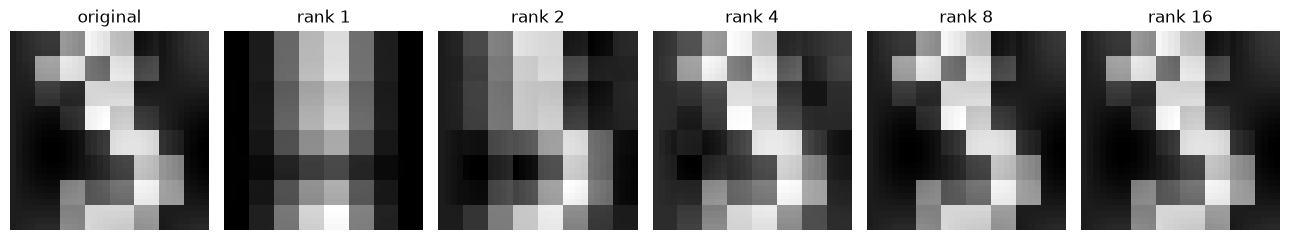

15:56:53 | INFO | figure saved -> figures/singular_spectrum.png


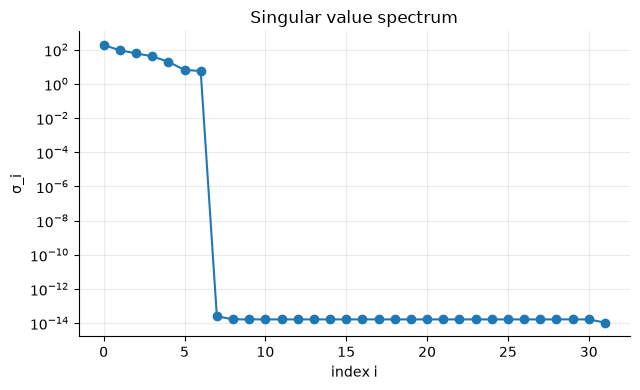

In [8]:
from sklearn.datasets import load_digits
img = load_digits().images[3]; img = np.kron(img, np.ones((4, 4)))           # 32x32 image
yy, xx = np.mgrid[0:32, 0:32]; img = img + 2 * np.sin(xx / 4) * np.cos(yy / 6)   # add low-rank texture
U, s, Vt = np.linalg.svd(img, full_matrices=False)
ks = [1, 2, 4, 8, 16]
fig, ax = plt.subplots(1, len(ks) + 1, figsize=(13, 2.6))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("original"); ax[0].axis("off")
errs = []
for a_, k in zip(ax[1:], ks):
    Ak = (U[:, :k] * s[:k]) @ Vt[:k]
    err = np.linalg.norm(img - Ak); errs.append(err)
    check(np.isclose(err ** 2, (s[k:] ** 2).sum()), f"k={k}: ||A-A_k||_F^2 = sum of discarded σ^2")
    check(np.isclose(np.linalg.norm(img - Ak, 2), s[k] if k < len(s) else 0), f"k={k}: spectral error = σ_(k+1)")
    a_.imshow(Ak, cmap="gray"); a_.set_title(f"rank {k}"); a_.axis("off")
show("lowrank_images")
plt.semilogy(s, "o-"); plt.xlabel("index i"); plt.ylabel("σ_i"); plt.title("Singular value spectrum"); show("singular_spectrum")
METRICS["frob_errors"] = dict(zip(ks, errs))

## 7 · Positive (semi)definite matrices
$S$ is PSD if $x^\top Sx\ge0\ \forall x$ ⇔ all eigenvalues $\ge0$. Every Gram matrix $X^\top X$ and every covariance matrix is PSD. A PD matrix has a Cholesky factorisation $S=LL^\top$ (fails if not PD — a useful numerical test).

In [9]:
X = rng.normal(size=(50, 4)); G = X.T @ X
check(np.all(np.linalg.eigvalsh(G) >= -1e-10), "Gram matrix X^T X is PSD")
L = np.linalg.cholesky(G); check(np.allclose(L @ L.T, G), "Cholesky: G = L L^T")
Bad = np.array([[1., 2.], [2., 1.]])               # eigenvalues 3 and -1 -> indefinite
print("eigs of Bad:", np.linalg.eigvalsh(Bad))
try: np.linalg.cholesky(Bad)
except np.linalg.LinAlgError: print("  Cholesky correctly refuses an indefinite matrix")

  ✅ Gram matrix X^T X is PSD
  ✅ Cholesky: G = L L^T
eigs of Bad: [-1.  3.]
  Cholesky correctly refuses an indefinite matrix


## 8 · Tensor contractions with `einsum`, and memory layout
`einsum` names each axis and sums repeated ones: batched matmul is `bij,bjk->bik`. Attention scores in Module 14 are `bqd,bkd->bqk`. We also show that a transpose is a *view* with swapped strides, not a copy.

In [10]:
Bt = rng.normal(size=(8, 4, 5)); Ct = rng.normal(size=(8, 5, 3))
out = np.einsum("bij,bjk->bik", Bt, Ct)
loops = np.stack([Bt[b] @ Ct[b] for b in range(8)])
check(np.allclose(out, loops), "einsum 'bij,bjk->bik' == looped matmul")
check(np.allclose(np.einsum("ii", np.eye(5)), 5), "einsum 'ii' = trace")
q, k = rng.normal(size=(2, 6, 16)), rng.normal(size=(2, 7, 16))
check(np.einsum("bqd,bkd->bqk", q, k).shape == (2, 6, 7), "attention-style scores have shape (B, Tq, Tk)")

M = np.arange(12.).reshape(3, 4)
print("C-order strides:", M.strides, "| transpose strides:", M.T.strides, "| shares memory:", np.shares_memory(M, M.T))
check(np.shares_memory(M, M.T) and not M.T.flags["C_CONTIGUOUS"], "transpose is a non-contiguous view (no copy)")
import time
big = rng.normal(size=(3000, 3000))
t0 = time.perf_counter(); big.sum(axis=1); t_row = time.perf_counter() - t0
t0 = time.perf_counter(); big.sum(axis=0); t_col = time.perf_counter() - t0
print(f"sum over contiguous axis: {t_row*1e3:.1f} ms ; strided axis: {t_col*1e3:.1f} ms")

  ✅ einsum 'bij,bjk->bik' == looped matmul
  ✅ einsum 'ii' = trace
  ✅ attention-style scores have shape (B, Tq, Tk)
C-order strides: (32, 8) | transpose strides: (8, 32) | shares memory: True
  ✅ transpose is a non-contiguous view (no copy)
sum over contiguous axis: 3.3 ms ; strided axis: 2.3 ms


In [11]:
save_metrics("01", METRICS)
log.info('notebook 01 finished OK')

15:56:53 | INFO | metrics saved -> metrics.json


15:56:53 | INFO | notebook 01 finished OK


## Wrap-up

## Exercises (do these next)

1. Show numerically that the eigenvalues of $A^\top A$ equal the squared singular values of $A$.
2. Replace the digit image with random noise: how does the singular spectrum change, and why is it incompressible?
3. Implement power iteration for the dominant eigenvector and compare with `np.linalg.eig`.

## Where to read more

- Wiki chapter: [Module 01](https://github.com/anuxlab/deep-learning-systems/wiki/Module-01) (derivations, worked example, Q&A).
- Strang, *Introduction to Linear Algebra*; Golub & Van Loan, *Matrix Computations*.
- Eckart & Young (1936), *The approximation of one matrix by another of lower rank*.